# Principal Component Analysis (PCA) of European Protein Consumption

| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week07** | Dimensionality Reduction in Machine Learning                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | November 4, 2026, 11:55 PM                                                                                                                                                                                                                                                                                         |
| **Student Name - Number     | Edward Chisaka - 1774058                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week05_ Lab implementation exercise.<br/> **_PCA –_**.<br/> _Principal Component Analysis of European protein consumption_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/04-assignment) |

# Import Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from matplotlib.colors import LinearSegmentedColormap
from sklearn.decomposition import PCA

try:
    from adjustText import adjust_text      # optional: keeps point labels from overlapping
except ImportError:
    adjust_text = None

# ---- plot style: quiet grid, text in ink colours, one blue for the data ----
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.edgecolor": GRID, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110,
})
DIVERGING = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", RED])

In [8]:
path = Path('data/protein.csv')
df = pd.read_csv(path)
print(f"{df.shape[0]} rows (countries) x {df.shape[1]} columns")
# df.head()
df

25 rows (countries) x 10 columns


,Country,RedMeat,WhiteMeat,Eggs,Milk,Fish,Cereals,Starch,Nuts,Fr&Veg
0,Albania,10.1,1.4,0.5,8.9,0.2,42.3,0.6,5.5,1.7
1,Austria,8.9,14.0,4.3,19.9,2.1,28.0,3.6,1.3,4.3
2,Belgium,13.5,9.3,4.1,17.5,4.5,26.6,5.7,2.1,4.0
3,Bulgaria,7.8,6.0,1.6,8.3,1.2,56.7,1.1,3.7,4.2
4,Czechoslovakia,9.7,11.4,2.8,12.5,2.0,34.3,5.0,1.1,4.0
5,Denmark,10.6,10.8,3.7,25.0,9.9,21.9,4.8,0.7,2.4
6,E Germany,8.4,11.6,3.7,11.1,5.4,24.6,6.5,0.8,3.6
7,Finland,9.5,4.9,2.7,33.7,5.8,26.3,5.1,1.0,1.4
8,France,18.0,9.9,3.3,19.5,5.7,28.1,4.8,2.4,6.5
9,Greece,10.2,3.0,2.8,17.6,5.9,41.7,2.2,7.8,6.5


# Exploratory Data Analysis

In [16]:
features =  [c for c in df.columns if c not in ['Country']]
# print(features)

X = df[features]

print("Column types:")
print(df.dtypes.to_string(), "\n")
print("Missing values:", int(df.isnull().sum().sum()), "\n")
print("Duplicate rows:", int(df.duplicated().sum()), "\n" )
print("Duplicate countries:", int(df["Country"].duplicated().sum()))
X.describe().T.round(2)


Column types:
Country          str
RedMeat      float64
WhiteMeat    float64
Eggs         float64
Milk         float64
Fish         float64
Cereals      float64
Starch       float64
Nuts         float64
Fr&Veg       float64 

Missing values: 0 

Duplicate rows: 0 

Duplicate countries: 0


,count,mean,std,min,25%,50%,75%,max
RedMeat,25.0,9.83,3.35,4.4,7.8,9.5,10.6,18.0
WhiteMeat,25.0,7.90,3.69,1.4,4.9,7.8,10.8,14.0
Eggs,25.0,2.94,1.12,0.5,2.7,2.9,3.7,4.7
Milk,25.0,17.11,7.11,4.9,11.1,17.6,23.3,33.7
Fish,25.0,4.28,3.40,0.2,2.1,3.4,5.8,14.2
Cereals,25.0,32.25,10.97,18.6,24.3,28.0,40.1,56.7
Starch,25.0,4.28,1.63,0.6,3.1,4.7,5.7,6.5
Nuts,25.0,3.07,1.99,0.7,1.5,2.4,4.7,7.8
Fr&Veg,25.0,4.14,1.80,1.4,2.9,3.8,4.9,7.9


**Distributions**. Histograms of each variable 
- (25 observation)

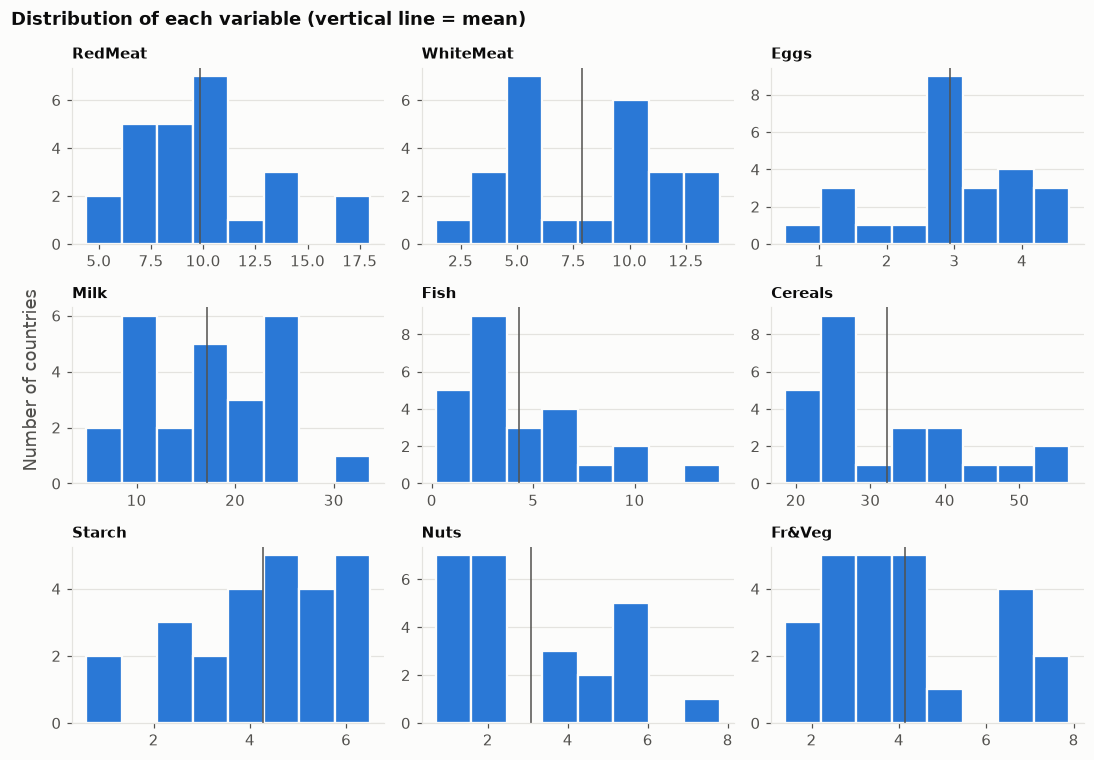

In [17]:
fig, axes = plt.subplots(3, 3, figsize=(10, 7))
for ax, col in zip(axes.ravel(), features):
    ax.hist(X[col], bins=8, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(X[col].mean(), color=INK2, lw=1)             # mean marker
    ax.set_title(col, fontsize=10)
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of each variable (vertical line = mean)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.supylabel("Number of countries", color=INK2)
fig.tight_layout()
plt.show()

**Scale of the Variables**: 

PCA looks for directions where the data varies the most. However, if some variables have much larger numerical values than others, they can dominate the PCA results. 

Therefore, comparing the spread of the variables to determine whether standardization is necessary will ensure that standardization ensures PCA identifies meaningful patterns in the data rather than simply favouring variables with larger numerical scales.


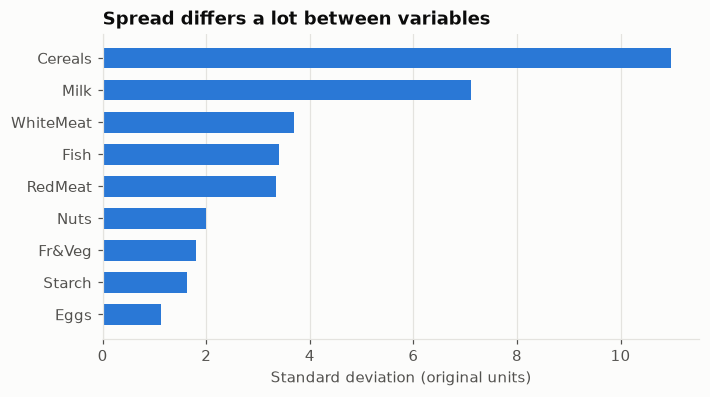

,mean,std
Cereals,32.25,10.97
Milk,17.11,7.11
WhiteMeat,7.90,3.69
Fish,4.28,3.40
RedMeat,9.83,3.35
Nuts,3.07,1.99
Fr&Veg,4.14,1.80
Starch,4.28,1.63
Eggs,2.94,1.12


In [18]:
stats = pd.DataFrame({"mean": X.mean(), "std": X.std()}).sort_values("std", ascending=False)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.barh(stats.index[::-1], stats["std"][::-1], color=BLUE, height=0.65)
ax.set_xlabel("Standard deviation (original units)")
ax.set_title("Spread differs a lot between variables")
ax.grid(axis="y", visible=False)
plt.show()
stats.round(2)

<!--  -->